## Lista 1
Karol Garbaczewski, Adam Freń

In [1]:
import numpy as np
from decimal import Decimal 
import cProfile
import timeit
import matplotlib.pyplot as plt


### Zadanie 1

Rozważmy dwa przybliżenia Pad´ego funkcji exp(−x):
$$ z_1 = \frac{6-2x}{6+4x+x^2}$$
$$ z_2 = \frac{6-4x+x^2}{6+2x}$$

Korzystając z dowolnej biblioteki do rysowania wykresów w Pythonie,
sporządź wykres:
- przybliżeń Pad´ego (na jednym rysunku),
- tych samych przybliżeń, ale na oddzielnych rysunkach w trybie wie-
lowykresowym,
- błędu każdego przybliżenia

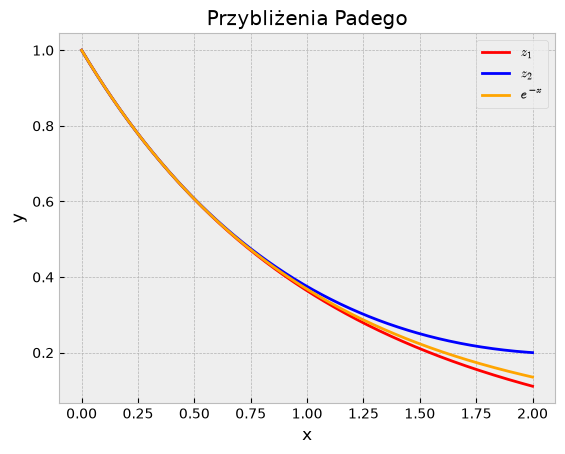

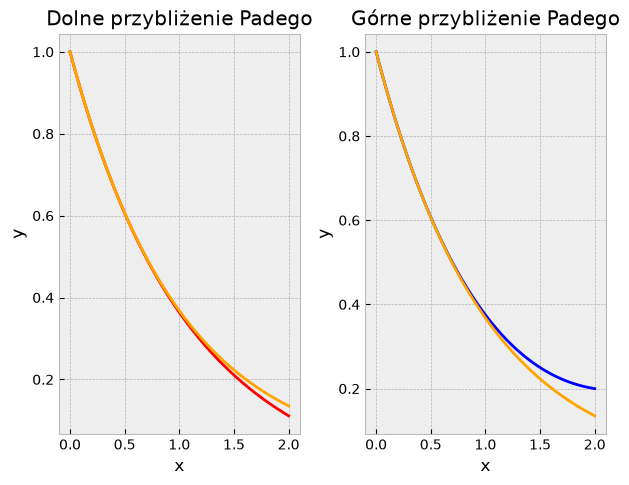

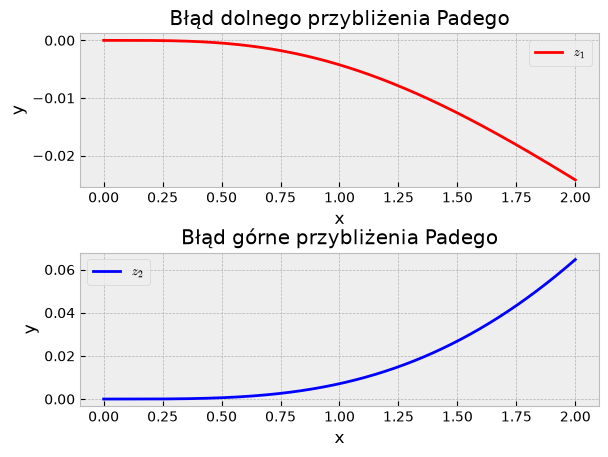

In [24]:
def z_1(x):
    return (6-(2*x))/(6+(4*x)+(x**2))
def z_2(x):
    return (6-(4*x)+(x**2))/(6+(2*x))
X=np.linspace(0,2,1000)
z_1_vect=[z_1(i) for i in X]
z_2_vect=[z_2(i) for i in X]
exp_vect=[np.exp(-1*i) for i in X]
plt.plot(X,z_1_vect,label="$z_1$",linewidth=2,color="red")
plt.plot(X,z_2_vect,label="$z_2$",linewidth=2,color="blue")
plt.plot(X,exp_vect,label="$e^{-x}$",linewidth=2,color="orange")
plt.legend()
plt.style.use("bmh")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Przybliżenia Padego")
plt.savefig("./zadanie1.png")
plt.show()

fig,ax = plt.subplots(1,2)
fig.tight_layout(pad=2)
ax[0].plot(X,z_1_vect,label="$z_1$",linewidth=2,color="red")
ax[0].plot(X,exp_vect,label="$e^{-x}$",linewidth=2,color="orange")
ax[0].set_title("Dolne przybliżenie Padego")
ax[0].set_xlabel("x")
ax[0].set_ylabel("y")
ax[1].plot(X,z_2_vect,label="$z_2$",linewidth=2,color="blue")
ax[1].plot(X,exp_vect,label="$e^{-x}$",linewidth=2,color="orange")
ax[1].set_title("Górne przybliżenie Padego")
ax[1].set_xlabel("x")
ax[1].set_ylabel("y")

fig,ax = plt.subplots(2,1)
fig.tight_layout(pad=3)
ax[0].plot(X,np.add(z_1_vect,np.multiply(exp_vect,-1)),label="$z_1$",linewidth=2,color="red")
ax[0].set_title("Błąd dolnego przybliżenia Padego")
ax[0].set_xlabel("x")
ax[0].set_ylabel("y")
ax[0].legend()
ax[1].plot(X,np.add(z_2_vect,np.multiply(exp_vect,-1)),label="$z_2$",linewidth=2,color="blue")
ax[1].set_title("Błąd górne przybliżenia Padego")
ax[1].set_xlabel("x")
ax[1].set_ylabel("y")
ax[1].legend()
fig.savefig("./zadanie1_2.png")
plt.show()



### Zadanie 2
Napisz program znajdujący dokładność maszynową na Twoim komputerze.

In [12]:
eps=1
while 1+eps!=1:
    eps/=2
print(2*eps)   

2.220446049250313e-16


### Zadanie 3
Jaki jest wynik działania
$$7/100 ∗ 100 − 7$$
wykonanego w Pythonie? Wyjaśnij przyczynę błędu. Sprawdź, które z
liczb od $1$ do $50$ są również podatne na błąd tego typu.

In [13]:
f = lambda x: x/100 * 100 - x
for i in range(1,51):
    if f(i) != 0:
        print(i,f(i))  

7 8.881784197001252e-16
14 1.7763568394002505e-15
28 3.552713678800501e-15
29 -3.552713678800501e-15


### Zadanie 4.

In [14]:
# chcemy sprawdzić błąd dla 32 bitowego standardu IEEE - sam python zapisuje float w precyzji 64 bitowej - trzeba uzyć numpy aby mieć precyzje 32 bitów


x_real = Decimal('1.7') # zapisuje 1.1 idealnie omijajac binarny zapis liczby - Binary-coded decimal
x_with_error = Decimal(float(np.float32(1.7))) 

print(f"błąd bezwzględny: {abs(x_real - x_with_error)}")
print(f"błąd względny: {abs(x_real - x_with_error) / x_real}")

błąd bezwzględny: 4.76837158203125E-8
błąd względny: 2.804924460018382352941176471E-8


### Zadanie 5. 

In [15]:
# rozwiązanie naiwne 
def W(dx, x_range):
    x_min, x_max = x_range
    arguments = np.arange(x_min, x_max, dx)

    return arguments **199 + 6 * arguments ** 4 + 5* arguments**3 - 13 * arguments **2 + arguments + 1

results= W(0.0001, (-10, 10))
print(results)

dx = 0.0001
x_range = (-10,10)
cProfile.run("W(dx, x_range)")
test = timeit.repeat(lambda: W(dx, x_range), number=100, repeat=5)
print(min(test))

[-1.00000000e+199 -9.98011969e+198 -9.96027870e+198 ...  9.94047695e+198
  9.96027869e+198  9.98011968e+198]
         5 function calls in 0.009 seconds

   Ordered by: standard name

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.009    0.009    0.009    0.009 3083704196.py:2(W)
        1    0.000    0.000    0.009    0.009 <string>:1(<module>)
        1    0.000    0.000    0.009    0.009 {built-in method builtins.exec}
        1    0.000    0.000    0.000    0.000 {built-in method numpy.arange}
        1    0.000    0.000    0.000    0.000 {method 'disable' of '_lsprof.Profiler' objects}


0.8529190999997809


### Zadanie 6. 

In [16]:
#def _inner_horner(x_powers, coefficients, x_arguments): zoptymalizowanie 
#

def horner(x_powers, coefficients, x_arguments):
    """ x_powers - posortowana lista z potęgami wielomianu (ints)
        coeffients -posortowana lista z współczynnikami wielomianu 
        x_arguments - wektor wartości wielomianu jakie chcemy otrzymać """
    if np.issubdtype(x_powers.dtype, np.floating):
        raise TypeError("x_powers should contain integers, not floats")

    
    if len(x_powers) == 0:
        return 0
    
    if x_powers[-1] == 0:
        return horner(x_powers[0:-1], coefficients[0:-1], x_arguments) + coefficients[-1]
    
    elif x_powers[-1] > 0:
        shift = x_powers[-1]
        return np.power(x_arguments, shift) * horner(x_powers - shift, coefficients, x_arguments) 
    


x_powers = np.array([199, 4,3,2,1,0])
coefficients = np.array([1, 6,5,-13,1,1])
x_arguments = np.arange(-10,10, 0.0001)
results_2 = horner(x_powers,coefficients, x_arguments)
print(results_2)
cProfile.run('horner(x_powers, coefficients, x_arguments)')
test =min(timeit.repeat(lambda: horner(x_powers, coefficients, x_arguments), number=100, repeat=5))
print(test)

[-1.00000000e+199 -9.98011969e+198 -9.96027870e+198 ...  9.94047695e+198
  9.96027869e+198  9.98011968e+198]
         99 function calls (88 primitive calls) in 0.007 seconds

   Ordered by: standard name

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
     12/1    0.006    0.001    0.006    0.006 3621222676.py:4(horner)
        1    0.000    0.000    0.006    0.006 <string>:1(<module>)
       24    0.000    0.000    0.000    0.000 numerictypes.py:230(issubclass_)
       12    0.000    0.000    0.000    0.000 numerictypes.py:418(issubdtype)
        1    0.000    0.000    0.007    0.007 {built-in method builtins.exec}
       36    0.000    0.000    0.000    0.000 {built-in method builtins.issubclass}
       12    0.000    0.000    0.000    0.000 {built-in method builtins.len}
        1    0.000    0.000    0.000    0.000 {method 'disable' of '_lsprof.Profiler' objects}


0.6228548999997656
